# 01 - Analisis exploratorio de CICIDS2017

Explora el dataset limpio generado por `python -m src.preprocess --dataset cicids2017`: resumen de limpieza, desbalance de clases, correlacion y distribucion de variables clave por clase.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().resolve()
while not (ROOT / 'AGENT.md').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import config
from src.data_loader import load_processed, split_features_target

DATASET = config.get_dataset('cicids2017')
sns.set_theme(style='whitegrid')
df = load_processed(DATASET.key)
X, y, attack = split_features_target(df)
numeric = X.select_dtypes('number')
print(df.shape)

(2496544, 71)


## 1. Resumen de limpieza

In [2]:
report = json.loads(DATASET.cleaning_report_file.read_text(encoding='utf-8'))
steps = pd.Series({
    'Filas crudas': report['rows_raw'],
    'Con inf/NaN (eliminadas)': -report['rows_removed_missing'],
    'Duplicados exactos (eliminados)': -report['rows_removed_duplicates'],
    'Etiquetas conflictivas (eliminadas)': -report['rows_removed_conflicting'],
    'Filas finales': report['rows_final'],
})
print(steps.to_string())
print('\nColumnas constantes eliminadas:', report['constant_columns_dropped'])
print('Variables finales:', report['n_features'])
raw = pd.Series(report['attack_type_counts_raw']); final = pd.Series(report['attack_type_counts_final'])
print(pd.DataFrame({'crudo': raw, 'final': final, 'retenido_%': (final / raw * 100).round(1)}).to_string())

Filas crudas                           2830743
Con inf/NaN (eliminadas)                 -2867
Duplicados exactos (eliminados)        -329896
Etiquetas conflictivas (eliminadas)      -1436
Filas finales                          2496544

Columnas constantes eliminadas: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Variables finales: 69
                              crudo    final  retenido_%
BENIGN                      2273097  2071536        91.1
Bot                            1966     1948        99.1
DDoS                         128027   128011       100.0
DoS GoldenEye                 10293    10282        99.9
DoS Hulk                     231073   172697        74.7
DoS Slowhttptest               5499     5228        95.1
DoS slowloris                  5796     5372        92.7
FTP - Patator                  7938     5931        74.7
Heartbleed                  

## 2. Desbalance de clases

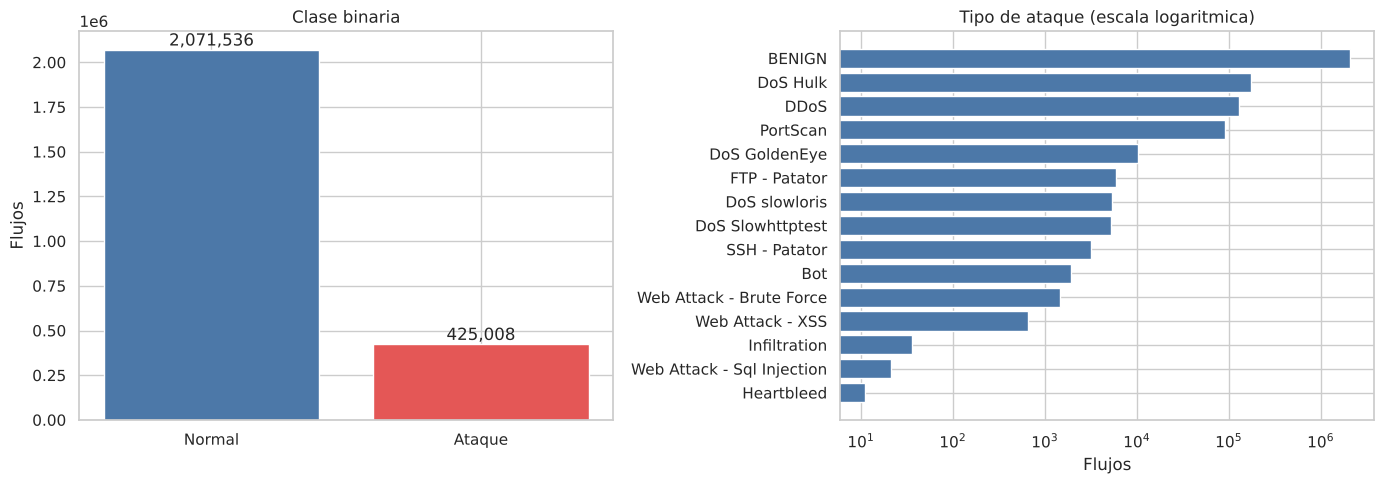

attack_type
BENIGN                        82.9761
DoS Hulk                       6.9174
DDoS                           5.1275
PortScan                       3.6102
DoS GoldenEye                  0.4118
FTP - Patator                  0.2376
DoS slowloris                  0.2152
DoS Slowhttptest               0.2094
SSH - Patator                  0.1289
Bot                            0.0780
Web Attack - Brute Force       0.0589
Web Attack - XSS               0.0261
Infiltration                   0.0014
Web Attack - Sql Injection     0.0008
Heartbleed                     0.0004


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
binary = y.map({0: 'Normal', 1: 'Ataque'}).value_counts()
axes[0].bar(binary.index, binary.values, color=['#4C78A8', '#E45756'])
axes[0].set_title('Clase binaria')
axes[0].set_ylabel('Flujos')
for i, v in enumerate(binary.values):
    axes[0].text(i, v, f'{v:,}', ha='center', va='bottom')
counts = attack.value_counts()
axes[1].barh(counts.index[::-1], counts.values[::-1], color='#4C78A8')
axes[1].set_xscale('log')
axes[1].set_title('Tipo de ataque (escala logaritmica)')
axes[1].set_xlabel('Flujos')
plt.tight_layout()
plt.show()
print((counts / len(df) * 100).round(4).to_string())

## 3. Correlacion entre variables

Pares con |r| > 0.95: 38 de 4761
Fwd Packet Length Mean       Avg Fwd Segment Size      1.0000
Fwd URG Flags                CWE Flag Count            1.0000
Fwd PSH Flags                SYN Flag Count            1.0000
Total Backward Packets       Subflow Bwd Packets       1.0000
Total Fwd Packets            Subflow Fwd Packets       1.0000
Bwd Packet Length Mean       Avg Bwd Segment Size      1.0000
Total Length of Bwd Packets  Subflow Bwd Bytes         1.0000
Total Length of Fwd Packets  Subflow Fwd Bytes         1.0000
Total Fwd Packets            Subflow Bwd Packets       0.9991
                             Total Backward Packets    0.9991

Variables que el filtro de correlacion descartaria: 22


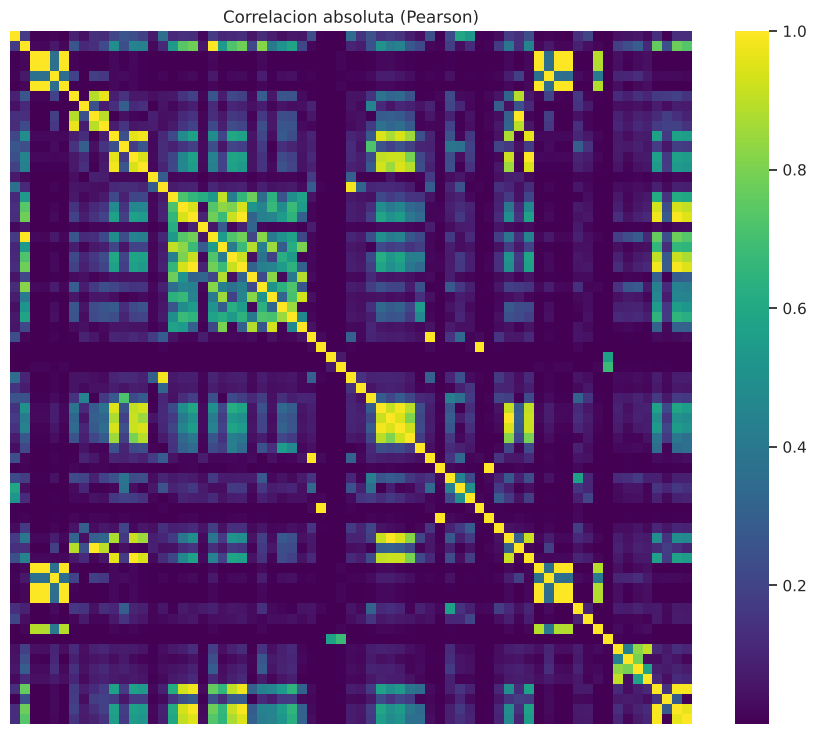

In [4]:
corr = numeric.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().sort_values(ascending=False)
print('Pares con |r| > 0.95:', int((pairs > 0.95).sum()), 'de', len(pairs))
print(pairs.head(10).round(4).to_string())
redundant = [c for c in upper.columns if (upper[c] > 0.95).any()]
print('\nVariables que el filtro de correlacion descartaria:', len(redundant))
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap='viridis', xticklabels=False, yticklabels=False)
plt.title('Correlacion absoluta (Pearson)')
plt.show()

## 4. Distribucion de variables clave por clase

Muestra estratificada por clase y `log1p`, porque las variables tienen colas muy pesadas.

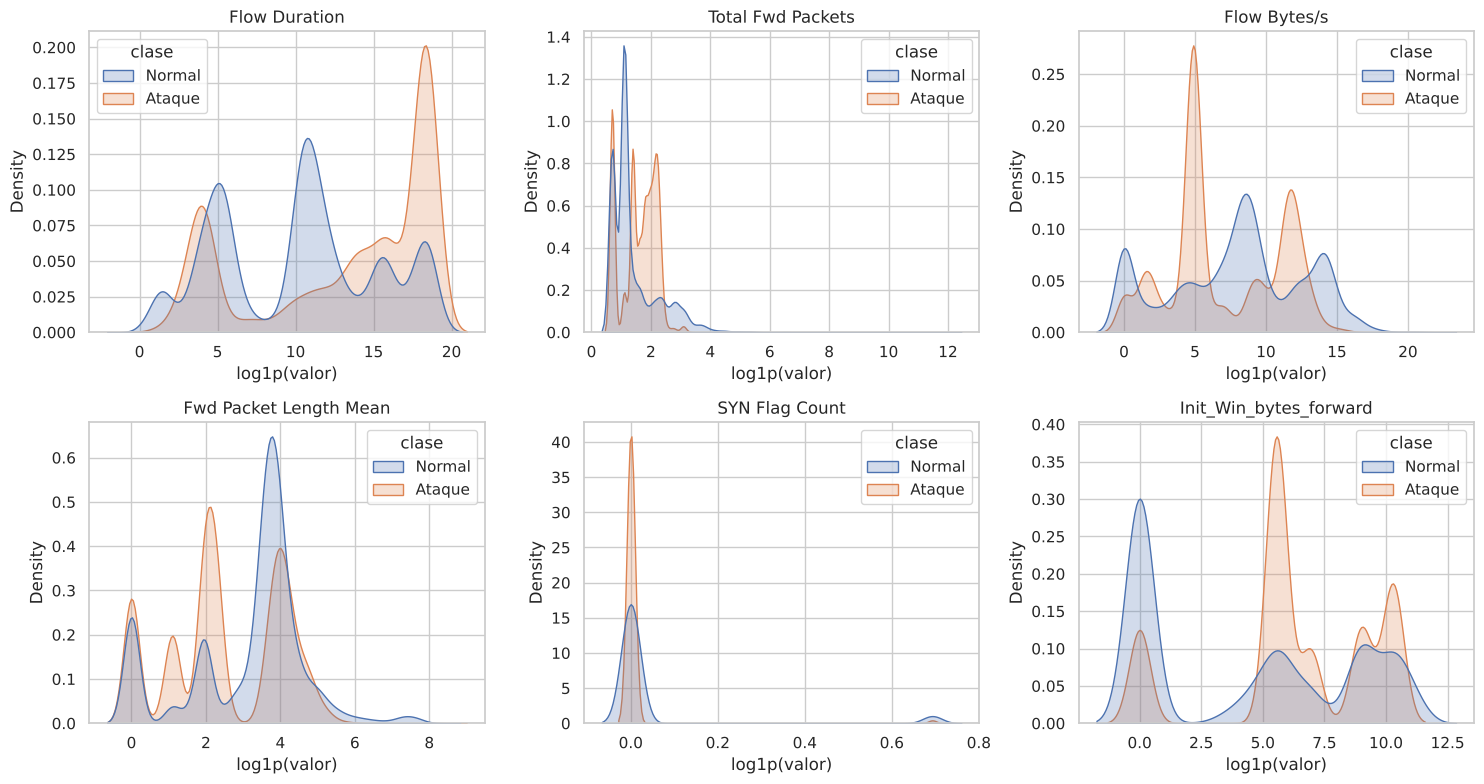

In [5]:
n = min(20000, int(y.value_counts().min()))
sample = df.groupby(config.LABEL_COLUMN, group_keys=False).sample(n=n, random_state=config.RANDOM_STATE)
sample = sample.assign(clase=sample[config.LABEL_COLUMN].map({0: 'Normal', 1: 'Ataque'}))
key_features = ['Flow Duration', 'Total Fwd Packets', 'Flow Bytes/s', 'Fwd Packet Length Mean', 'SYN Flag Count', 'Init_Win_bytes_forward']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feature in zip(axes.ravel(), key_features):
    values = np.log1p(sample[feature].clip(lower=0))
    sns.kdeplot(data=sample.assign(v=values), x='v', hue='clase', common_norm=False, fill=True, ax=ax)
    ax.set_title(feature)
    ax.set_xlabel('log1p(valor)')
plt.tight_layout()
plt.show()

## 5. Valores negativos

Algunas variables contienen valores sin sentido fisico (duracion o tasas negativas) y otros centinelas (`Init_Win_bytes_* = -1` indica ausencia de ventana TCP). No se modifican.

In [6]:
print(pd.Series(report['negative_value_counts']).sort_values(ascending=False).to_string())

Init_Win_bytes_backward    1193808
Init_Win_bytes_forward      892949
Flow IAT Min                  2880
Flow Duration                  107
Flow Packets/s                 107
Flow IAT Mean                  107
Flow IAT Max                   107
Flow Bytes/s                    78
min_seg_size_forward            35
Fwd Header Length               35
Bwd Header Length               22
Fwd IAT Min                     17
